In [ ]:
# Importando bibliotecas
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer # Permite tratar valores ausentes na base de dados
from sklearn.pipeline import Pipeline # Permite criar um pipeline de pré-processamento e treinamento do modelo
from sklearn.compose import ColumnTransformer # Permite aplicar diferentes transformações em diferentes colunas
from sklearn.preprocessing import OneHotEncoder # Permite transformar variáveis categóricas em variáveis numéricas
from sklearn.tree import DecisionTreeClassifier # Permite criar um modelo de árvore de decisão
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score # Permite calcular as métricas do modelo
import matplotlib.pyplot as plt # Permite criar gráficos
import seaborn as sns # Permite criar gráficos



In [ ]:
!pip install seaborn # Instalação da biblioteca seaborn para visualização de dados

Importando a base de dados


In [5]:
df = pd.read_csv('consumo_energetico_alunos.csv') # Lê o arquivo CSV e cria um DataFrame

In [6]:
df.head()

,timestamp,turno,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
0,2026-10-12 22:00:00,noite,1102.0,21.80,7.0,4.86,283.36
1,2027-11-15 14:00:00,tarde,1356.0,21.31,6.0,6.90,335.73
2,2028-12-27 06:00:00,manha,796.0,28.89,3.0,6.74,197.15
3,2027-04-25 14:00:00,tarde,1406.0,22.52,7.0,6.05,291.80
4,2028-03-27 06:00:00,manha,1431.0,23.98,7.0,5.44,269.41


In [9]:
# Exibir quantidade de linhas e colunas do DataFrame
#df.shape
print(f"Quantidade de linhas {len(df)} | Quantidade de colunas {len(df.columns)} ")

Quantidade de linhas 5050 | Quantidade de colunas 7 


In [ ]:
df.info() # Exibe informações sobre o DataFrame, como o número de linhas, colunas, tipos de dados e valores ausentes

<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               5050 non-null   str    
 1   turno                   5050 non-null   str    
 2   producao_unidades       4999 non-null   float64
 3   temperatura_ambiente_c  5000 non-null   float64
 4   maquinas_ativas         5000 non-null   float64
 5   horas_operacao_turno    4999 non-null   float64
 6   consumo_kwh             5050 non-null   float64
dtypes: float64(5), str(2)
memory usage: 276.3 KB


In [15]:
'''
Exploração dos dados
Quais variaveis são numericas e quais são categóricas?
Há Dados ausentes e repetidos ?
'''
print("Tipos de dados", df.dtypes) # Exibe os tipos de dados das colunas do DataFrame
print("\n Dados ausentes", df.isna().sum())
print("\n Dados duplicados", df.duplicated().sum()) # Verificando dados duplicados no DataFrame
print(df['turno'].value_counts()) # Exibe a contagem de valores únicos na coluna 'turno'
display(df.select_dtypes(include=['number']).describe().round(2)) # Exibe as primeiras linhas das colunas categóricas do DataFrame

Tipos de dados timestamp                     str
turno                         str
producao_unidades         float64
temperatura_ambiente_c    float64
maquinas_ativas           float64
horas_operacao_turno      float64
consumo_kwh               float64
dtype: object

 Dados ausentes timestamp                  0
turno                      0
producao_unidades         51
temperatura_ambiente_c    50
maquinas_ativas           50
horas_operacao_turno      51
consumo_kwh                0
dtype: int64

 Dados duplicados 50
turno
manha    1685
tarde    1683
noite    1682
Name: count, dtype: int64


,producao_unidades,temperatura_ambiente_c,maquinas_ativas,horas_operacao_turno,consumo_kwh
count,4999.00,5000.00,5000.00,4999.00,5050.00
mean,1902.49,26.33,8.97,5.99,399.25
std,940.45,6.21,3.74,1.16,176.52
min,311.00,14.00,3.00,4.00,71.97
25%,1152.00,23.01,6.00,4.98,252.84
50%,1821.00,26.12,9.00,5.99,384.32
75%,2505.00,29.21,12.00,6.99,519.82
max,11239.63,124.86,15.00,8.00,884.82


Limpeza e analise de outliers
Remove dados duplicados, manter um registro de quantas foram removidas
Converter data sem usá-las diretamente como preditores
O limite de 50 ºC é somente de exemplo 

In [22]:
# Limpeza e análise de outliers
# Varre o dataframe em busca de valores duplicados e remove-os, caso existam
df1 = df.drop_duplicates().copy() # Cria uma cópia do DataFrame sem valores duplicados
# Converter a coluna timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
print('Removidas',len(df) - len(df1), 'linhas duplicadas') # Exibe a quantidade de linhas duplicadas removidas
print('Quantidade de linhas e colunas do DataFrame após remoção de duplicados:', df1.shape) # Exibe a quantidade de linhas e colunas do DataFrame após a remoção de duplicados
print('Valores ausentes por coluna após remoção de duplicados:\n', df1.isna().sum()) # Exibe a quantidade de valores ausentes por coluna após a remoção de duplicados
print('Datas inválidas na coluna timestamp:', df1['timestamp'].isna().sum()) # Exibe a quantidade de datas inválidas na coluna timestamp
print('Temperaturas cima de 50º C para investigar:', (df1['temperatura_ambiente_c'] > 50).sum()) # Exibe a quantidade de temperaturas acima de 50º C para investigar

Removidas 50 linhas duplicadas
Quantidade de linhas e colunas do DataFrame após remoção de duplicados: (5000, 7)
Valores ausentes por coluna após remoção de duplicados:
 timestamp                  0
turno                      0
producao_unidades         50
temperatura_ambiente_c    50
maquinas_ativas           50
horas_operacao_turno      50
consumo_kwh                0
dtype: int64
Datas inválidas na coluna timestamp: 0
Temperaturas cima de 50º C para investigar: 25


producao_unidades            Axes(0.125,0.11;0.227941x0.77)
temperatura_ambiente_c    Axes(0.398529,0.11;0.227941x0.77)
consumo_kwh               Axes(0.672059,0.11;0.227941x0.77)
dtype: object

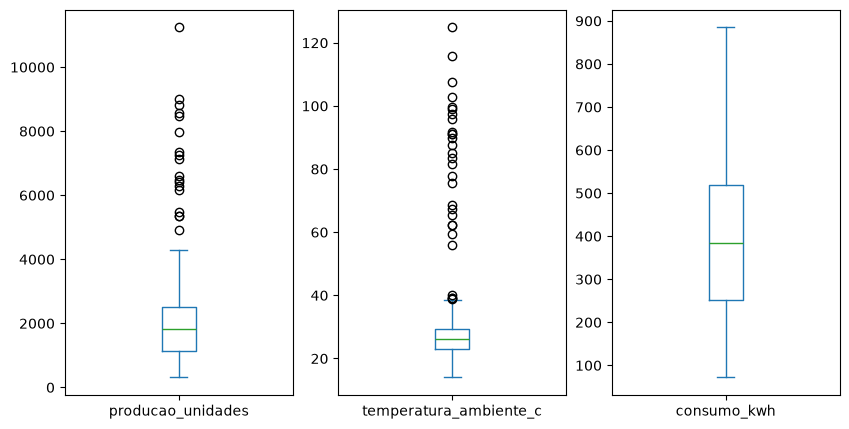

In [23]:
# Visualização dos outilers
df[['producao_unidades','temperatura_ambiente_c','consumo_kwh']].plot(kind='box',subplots= True,layout=(1,3),figsize=(10,5),sharey=False) # Cria um boxplot para visualizar os outliers nas colunas 'producao_unidades' e 'temperatura_ambiente_c'

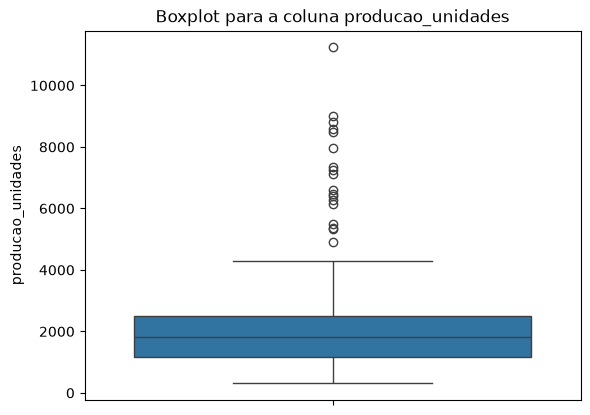

In [25]:
# Exibindo boxplot com a seaborn
sns.boxplot(data=df['producao_unidades']) # Cria um boxplot para visualizar os outliers nas colunas 'producao_unidades' 
plt.title('Boxplot para a coluna producao_unidades') # Adiciona um título ao gráfico
plt.show() # Exibe o gráfico